In [1]:

import platform
import sys

print("Python version:", sys.version)
print("Processor:", platform.machine())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print("CUDA available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed.")


Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Processor: AMD64
PyTorch version: 2.14.1+cu126
MPS available: False
CUDA available: True


In [2]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]


In [3]:

import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Python environment: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
MPS available: False



# IAI600 - CIFAR-10 Image Classification Project

## 1. Dataset Loading and Exploration

This project compares Multilayer Perceptron (MLP) and
Convolutional Neural Network (CNN) architectures
for image classification using the CIFAR-10 dataset.


In [4]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torchvision.datasets import CIFAR10

# Use Apple GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Classes:", classes)


Device: cpu


100.0%


Training images: 50000
Test images: 10000
Image shape: torch.Size([3, 32, 32])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



## 1.2 Dataset Visualization

In this section, we visualize sample images from
the CIFAR-10 dataset to understand its structure,
image characteristics, and class labels.


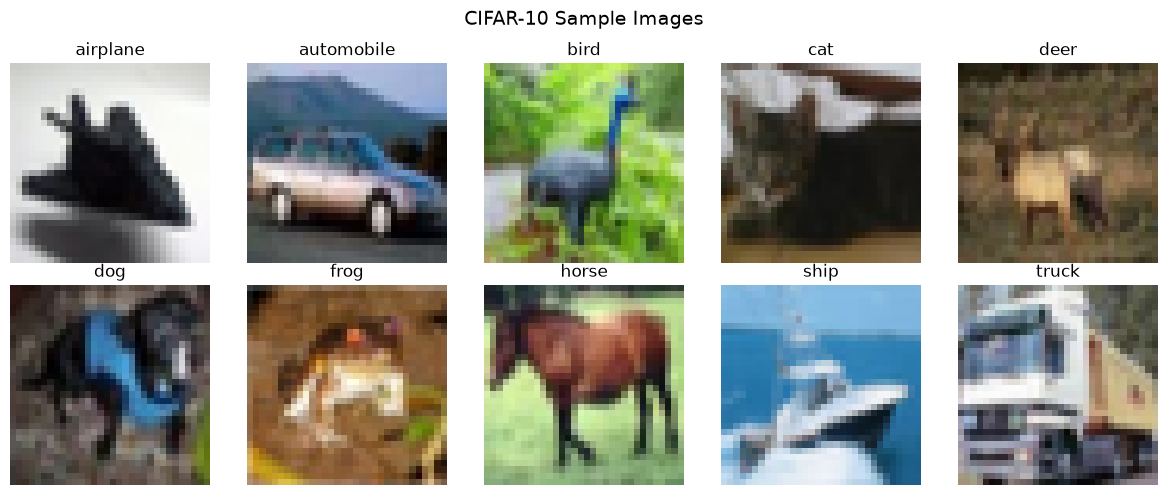

In [7]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = train_dataset.classes

# Display one example from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_idx in range(10):

    # Find the first image belonging to this class
    image_idx = train_dataset.targets.index(class_idx)

    # Get image and label
    image, label = train_dataset[image_idx]

    # Convert from [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Display image
    ax = axes[class_idx // 5, class_idx % 5]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=14)
plt.tight_layout()
plt.show()



## 1.3 Class Distribution Analysis

This section examines the number of images in each
CIFAR-10 class to determine whether the dataset
is balanced across all categories.


Class Distribution:
---------------------------------------------
airplane     | Train:  5000 | Test:  1000
automobile   | Train:  5000 | Test:  1000
bird         | Train:  5000 | Test:  1000
cat          | Train:  5000 | Test:  1000
deer         | Train:  5000 | Test:  1000
dog          | Train:  5000 | Test:  1000
frog         | Train:  5000 | Test:  1000
horse        | Train:  5000 | Test:  1000
ship         | Train:  5000 | Test:  1000
truck        | Train:  5000 | Test:  1000


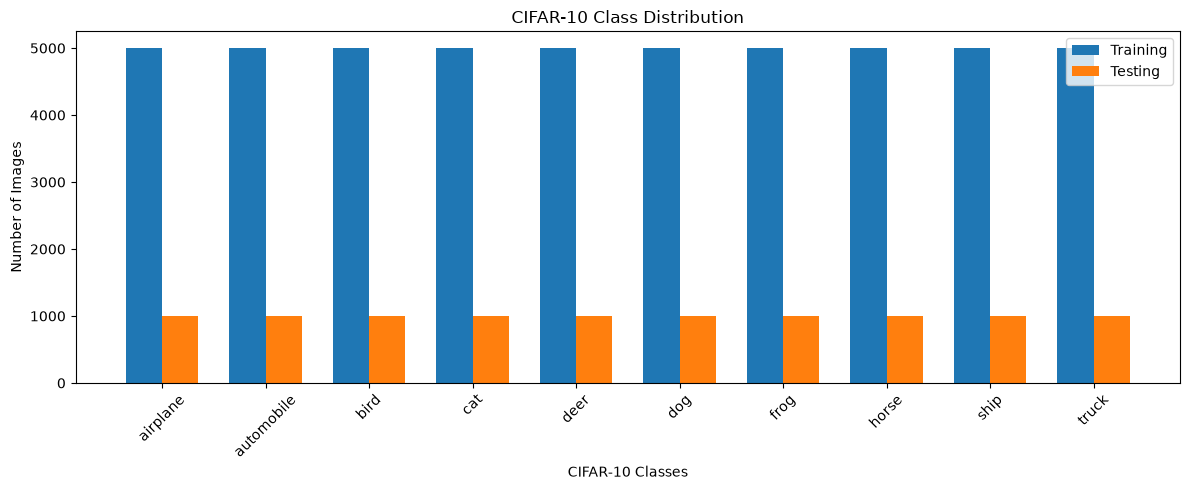

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Count images for each class
train_counts = np.bincount(
    train_dataset.targets, minlength=10
)

test_counts = np.bincount(
    test_dataset.targets, minlength=10
)

# Display the number of images
print("Class Distribution:")
print("-" * 45)

for i, class_name in enumerate(classes):
    print(
        f"{class_name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

# Create bar chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    test_counts,
    width,
    label="Testing"
)

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(x, classes, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 1.4 Stratified Train/Validation Split

The original CIFAR-10 training dataset contains
50,000 images.

We split this dataset into 90% training and
10% validation data using stratified sampling.

Stratification preserves the class distribution,
ensuring that all 10 classes are equally represented.

A fixed random seed (42) is used for reproducibility.
The original test set remains unchanged.


In [17]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Original labels from CIFAR-10 training dataset
labels = np.array(train_dataset.targets)

# Indices for all 50,000 training images
indices = np.arange(len(train_dataset))

# Stratified split: 90% training, 10% validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

# Verify dataset sizes
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

# Verify class distribution
train_labels = labels[train_indices]
val_labels = labels[val_indices]

print("\nClass Distribution After Split:")
print("-" * 45)

for i, class_name in enumerate(classes):
    train_count = np.sum(train_labels == i)
    val_count = np.sum(val_labels == i)

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:4d}"
    )


Training samples: 45000
Validation samples: 5000
Test samples: 10000

Class Distribution After Split:
---------------------------------------------
airplane     | Train:  4500 | Validation:  500
automobile   | Train:  4500 | Validation:  500
bird         | Train:  4500 | Validation:  500
cat          | Train:  4500 | Validation:  500
deer         | Train:  4500 | Validation:  500
dog          | Train:  4500 | Validation:  500
frog         | Train:  4500 | Validation:  500
horse        | Train:  4500 | Validation:  500
ship         | Train:  4500 | Validation:  500
truck        | Train:  4500 | Validation:  500



## 1.5 Data Normalization

We compute channel-wise mean and standard deviation
using only the training subset.

The same normalization parameters will be applied
to training, validation, and test images to avoid
data leakage and ensure consistent preprocessing.


In [18]:

from torch.utils.data import DataLoader

# Temporary DataLoader for computing statistics
stats_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images, labels_batch in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(
    channel_sum_sq / total_pixels - mean ** 2
)

print("Training mean:", mean)
print("Training std:", std)


Training mean: tensor([0.4911, 0.4821, 0.4464])
Training std: tensor([0.2469, 0.2434, 0.2616])


In [19]:

from torchvision import transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Normalization transform
normalized_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Load the existing datasets with normalization
normalized_train_full = CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normalized_transform
)

normalized_test = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=normalized_transform
)

# Reuse exactly the same indices
train_final = Subset(normalized_train_full, train_indices)
val_final = Subset(normalized_train_full, val_indices)
test_final = normalized_test

print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Testing:", len(test_final))


Training: 45000
Validation: 5000
Testing: 10000


In [20]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Image dtype: torch.float32



## 1.6 Final Preprocessing Verification

This section verifies that the normalized training
dataset has approximately zero channel-wise mean
and unit standard deviation.

It also verifies that the training, validation,
and test datasets contain the expected samples.


In [21]:

# Verify normalization using the complete training set
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images_batch, _ in train_loader:
    channel_sum += images_batch.sum(dim=(0, 2, 3))
    channel_sum_sq += (images_batch ** 2).sum(dim=(0, 2, 3))
    total_pixels += images_batch.shape[0] * 32 * 32

verified_mean = channel_sum / total_pixels
verified_std = torch.sqrt(
    channel_sum_sq / total_pixels - verified_mean ** 2
)

print("Normalized training mean:", verified_mean)
print("Normalized training std:", verified_std)

print("\nDataset sizes:")
print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

# Final checks
assert len(train_final) == 45000
assert len(val_final) == 5000
assert len(test_final) == 10000

assert set(train_indices).isdisjoint(set(val_indices))

assert torch.allclose(
    verified_mean, torch.zeros(3), atol=1e-4
)

assert torch.allclose(
    verified_std, torch.ones(3), atol=1e-4
)

print("\nAll preprocessing checks passed!")


Normalized training mean: tensor([ 1.4129e-07,  5.4724e-07, -4.8163e-08])
Normalized training std: tensor([1.0000, 1.0000, 1.0000])

Dataset sizes:
Training: 45000
Validation: 5000
Test: 10000

All preprocessing checks passed!



## 1.7 Reproducibility and Group Handoff

We save the exact training and validation indices
and normalization parameters to ensure that the
MLP and CNN models use identical data partitions
and preprocessing settings.


In [22]:

import json
from pathlib import Path

# Create a folder for shared configuration files
config_dir = Path("config")
config_dir.mkdir(exist_ok=True)

# Save exact dataset indices
np.savez(
    config_dir / "split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

# Save preprocessing parameters
config = {
    "dataset": "CIFAR-10",
    "random_state": 42,
    "training_samples": 45000,
    "validation_samples": 5000,
    "test_samples": 10000,
    "batch_size": BATCH_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "classes": classes
}

with open(
    config_dir / "preprocessing_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("Configuration files saved successfully!")
print("Files:")
print(config_dir / "split_indices.npz")
print(config_dir / "preprocessing_config.json")


Configuration files saved successfully!
Files:
config\split_indices.npz
config\preprocessing_config.json



## 1.8 Configuration Verification

This section verifies that the saved preprocessing
configuration and dataset indices can be reloaded
correctly for reproducible experiments.


In [23]:

import json
import numpy as np

# Load saved dataset indices
saved_indices = np.load("config/split_indices.npz")

saved_train = saved_indices["train_indices"]
saved_val = saved_indices["val_indices"]

# Load saved preprocessing configuration
with open("config/preprocessing_config.json", "r") as file:
    saved_config = json.load(file)

# Verify saved values
assert np.array_equal(saved_train, train_indices)
assert np.array_equal(saved_val, val_indices)

assert len(saved_train) == 45000
assert len(saved_val) == 5000

assert np.allclose(saved_config["mean"], mean.numpy())
assert np.allclose(saved_config["std"], std.numpy())

print("Training indices:", len(saved_train))
print("Validation indices:", len(saved_val))
print("Saved mean:", saved_config["mean"])
print("Saved std:", saved_config["std"])
print("Batch size:", saved_config["batch_size"])

print("\nAll configuration checks passed!")


Training indices: 45000
Validation indices: 5000
Saved mean: [0.4911373257637024, 0.4821110665798187, 0.44644901156425476]
Saved std: [0.246869295835495, 0.24343018233776093, 0.261603444814682]
Batch size: 64

All configuration checks passed!


In [24]:

from data_preparation import get_cifar10_loaders

# Load datasets using the shared module
train_loader_shared, val_loader_shared, test_loader_shared = (
    get_cifar10_loaders()
)

# Check dataset sizes
print("Training:", len(train_loader_shared.dataset))
print("Validation:", len(val_loader_shared.dataset))
print("Testing:", len(test_loader_shared.dataset))

# Check one batch
images, labels = next(iter(train_loader_shared))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("\nShared data preparation module works!")


Training: 45000
Validation: 5000
Testing: 10000

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])

Shared data preparation module works!


# 2.0 Build our MLP model

An MLP does not directly understand the spatial structure of an image. First, it converts the image into a long vector of numbers, then learns patterns using fully connected layers.

In [25]:

import torch
import torch.nn as nn

# Select the available device
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Using device:", device)


class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = MLP().to(device)

print(model)


Using device: cuda
MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


# 2.1 Getting ready for MLP Training 
Adding training loop and defining evaluation function

In [26]:

import torch.optim as optim

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training settings
num_epochs = 10

print("Model is ready for training.")


Model is ready for training.


In [27]:

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, data_loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    return epoch_loss, epoch_accuracy

print("Training and evaluation functions are ready.")


Training and evaluation functions are ready.


# 2.2 MLP Training
Train the data using training and validation loaders

In [31]:

# Use the data loaders created in the data-preparation section.
# Check that your loader variables are named train_loader and val_loader.

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )


Epoch [1/10] Train Loss: 1.6681 | Train Accuracy: 40.87% | Validation Loss: 1.5621 | Validation Accuracy: 44.22%
Epoch [2/10] Train Loss: 1.4722 | Train Accuracy: 48.06% | Validation Loss: 1.4955 | Validation Accuracy: 47.28%
Epoch [3/10] Train Loss: 1.3615 | Train Accuracy: 52.07% | Validation Loss: 1.4872 | Validation Accuracy: 48.62%
Epoch [4/10] Train Loss: 1.2861 | Train Accuracy: 54.76% | Validation Loss: 1.4452 | Validation Accuracy: 49.98%
Epoch [5/10] Train Loss: 1.2190 | Train Accuracy: 56.62% | Validation Loss: 1.4440 | Validation Accuracy: 50.96%
Epoch [6/10] Train Loss: 1.1448 | Train Accuracy: 59.54% | Validation Loss: 1.4382 | Validation Accuracy: 50.78%
Epoch [7/10] Train Loss: 1.0800 | Train Accuracy: 61.50% | Validation Loss: 1.5156 | Validation Accuracy: 49.30%
Epoch [8/10] Train Loss: 1.0205 | Train Accuracy: 63.92% | Validation Loss: 1.5028 | Validation Accuracy: 50.82%
Epoch [9/10] Train Loss: 0.9620 | Train Accuracy: 65.85% | Validation Loss: 1.5326 | Validation 

In [29]:
from data_preparation import get_cifar10_loaders
import inspect

print(inspect.signature(get_cifar10_loaders))



(project_dir='.', download=True)


In [30]:
import torch

device = torch.device("cpu")
model = model.to(device)

print("Using device:", device)

Using device: cpu


# 2.3 Plotting the results
Our model shows traces of overfitting after epoch 4. Validation accuracy increase plateaued around epoch 4 which is a clear indication of images fitting while not improving on unseen validation images

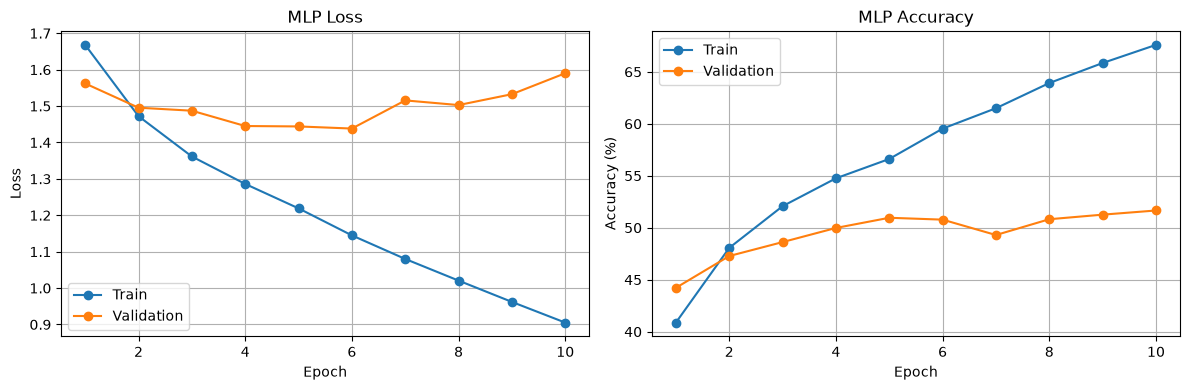

In [32]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Train")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_accuracy"], marker="o", label="Train")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MLP Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Saving MLP Model

In [33]:
torch.save(model.state_dict(), "mlp_cifar10.pth")
print("MLP model saved successfully.")


MLP model saved successfully.


# 2.4 Evaluating the MLP model
Running the evaluation function on test set to get the final results

In [34]:

criterion = torch.nn.CrossEntropyLoss()

test_loss, test_accuracy = evaluate(
    model=model,
    data_loader=test_loader,
    criterion=criterion,
    device=device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")


Test Loss: 1.5446
Test Accuracy: 52.27%


In [35]:
train_loader, val_loader, test_loader = get_cifar10_loaders()

# 3.0 Build our CNN model
Our CNN model has three convolutional layers, pooling layers to reduce image dimensions, and a final classifier for the 10 CIFAR-10 classes

In [37]:

import torch
import torch.nn as nn
import torch.optim as optim

class CIFAR10_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 x 16 x 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 x 8 x 8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 128 x 4 x 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = CIFAR10_CNN().to(device)

print(cnn_model)
print("Using device:", device)


CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Using device: cpu


# 3.1 Training CNN model

In [38]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 10

cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    # Training
    cnn_model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_total += loss.item() * batch_size
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_total / train_total
    train_acc = 100.0 * train_correct / train_total

    # Validation
    cnn_model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_total += loss.item() * batch_size
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_accuracy"].append(train_acc)
    cnn_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )


Epoch [1/10] Train Loss: 1.4306 | Train Accuracy: 48.17% | Validation Loss: 1.0642 | Validation Accuracy: 61.56%
Epoch [2/10] Train Loss: 1.0134 | Train Accuracy: 63.91% | Validation Loss: 0.9179 | Validation Accuracy: 67.02%
Epoch [3/10] Train Loss: 0.8396 | Train Accuracy: 70.56% | Validation Loss: 0.7727 | Validation Accuracy: 72.60%
Epoch [4/10] Train Loss: 0.7323 | Train Accuracy: 74.45% | Validation Loss: 0.7890 | Validation Accuracy: 72.92%
Epoch [5/10] Train Loss: 0.6380 | Train Accuracy: 77.69% | Validation Loss: 0.7141 | Validation Accuracy: 75.20%
Epoch [6/10] Train Loss: 0.5629 | Train Accuracy: 80.25% | Validation Loss: 0.7520 | Validation Accuracy: 75.22%
Epoch [7/10] Train Loss: 0.4938 | Train Accuracy: 82.68% | Validation Loss: 0.7178 | Validation Accuracy: 75.52%
Epoch [8/10] Train Loss: 0.4287 | Train Accuracy: 84.73% | Validation Loss: 0.7555 | Validation Accuracy: 76.34%
Epoch [9/10] Train Loss: 0.3787 | Train Accuracy: 86.39% | Validation Loss: 0.7468 | Validation 

# 3.2 Evaluating the CNN model
Running the evaluation function on test set to get the final results

In [39]:

test_loss, test_accuracy = evaluate(
    model=cnn_model,
    data_loader=test_loader,
    criterion=criterion,
    device=device
)

print(f"CNN Test Loss: {test_loss:.4f}")
print(f"CNN Test Accuracy: {test_accuracy:.2f}%")


CNN Test Loss: 0.8509
CNN Test Accuracy: 75.36%


# Saving CNN model

In [40]:

import torch
import json

# Save the trained CNN from epoch 10
torch.save(cnn_model.state_dict(), "cnn_cifar10.pth")

# Save the training history
with open("cnn_training_history.json", "w") as f:
    json.dump(cnn_history, f, indent=2)

# Save a record of the final test results
results = {
    "MLP_test_accuracy": 52.27,
    "MLP_test_loss": 1.5446,
    "CNN_test_accuracy": 75.36,
    "CNN_test_loss": 0.8509,
    "CNN_best_validation_accuracy": 76.34,
    "CNN_best_validation_epoch": 8
}

with open("model_comparison.json", "w") as f:
    json.dump(results, f, indent=2)

print("CNN weights, training history, and comparison results saved.")


CNN weights, training history, and comparison results saved.


# 3.3 Plotting the results
Our model shows traces of overfitting at late epochs. 

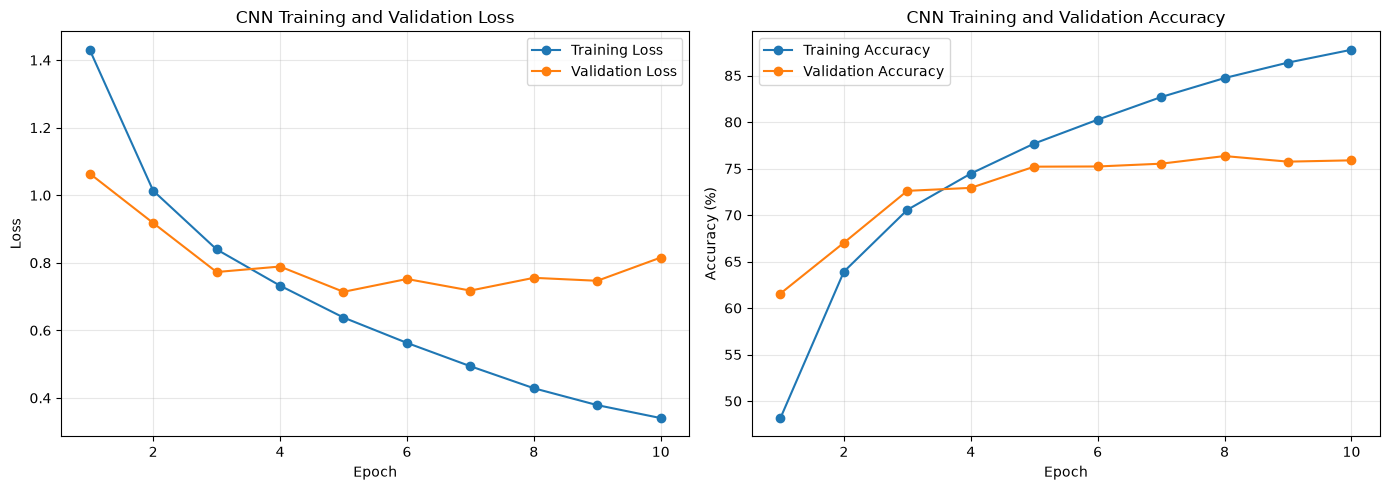

In [41]:

import matplotlib.pyplot as plt

epochs = range(1, len(cnn_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, cnn_history["train_loss"], marker="o",
             label="Training Loss")
axes[0].plot(epochs, cnn_history["val_loss"], marker="o",
             label="Validation Loss")
axes[0].set_title("CNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(epochs, cnn_history["train_accuracy"], marker="o",
             label="Training Accuracy")
axes[1].plot(epochs, cnn_history["val_accuracy"], marker="o",
             label="Validation Accuracy")
axes[1].set_title("CNN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()


# 3.4 Generating Confusion Matrix

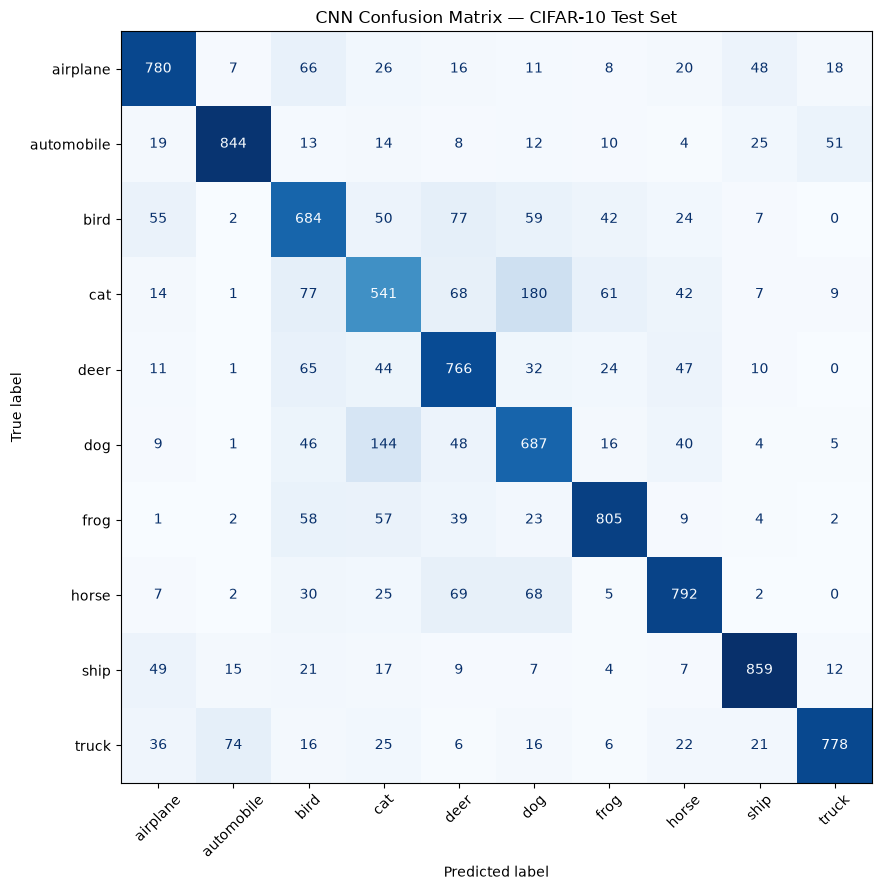

In [42]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

cnn_model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(10, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("CNN Confusion Matrix — CIFAR-10 Test Set")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 3.5 Calculating overall Accuracy for every class

In [43]:

print("CNN per-class test accuracy:")
print("-" * 36)

for i, name in enumerate(class_names):
    total = cm[i].sum()
    correct = cm[i, i]
    accuracy = 100.0 * correct / total if total > 0 else 0.0

    print(f"{name:12s}: {accuracy:6.2f}% ({correct}/{total})")

print("-" * 36)
print(f"Overall accuracy: {100 * np.trace(cm) / cm.sum():.2f}%")


CNN per-class test accuracy:
------------------------------------
airplane    :  78.00% (780/1000)
automobile  :  84.40% (844/1000)
bird        :  68.40% (684/1000)
cat         :  54.10% (541/1000)
deer        :  76.60% (766/1000)
dog         :  68.70% (687/1000)
frog        :  80.50% (805/1000)
horse       :  79.20% (792/1000)
ship        :  85.90% (859/1000)
truck       :  77.80% (778/1000)
------------------------------------
Overall accuracy: 75.36%


# Saving confusion matrix

<Figure size 1000x800 with 0 Axes>

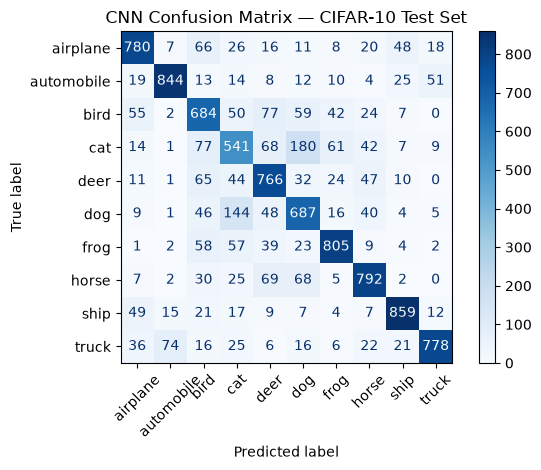

In [44]:

plt.figure(figsize=(10, 8))

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("CNN Confusion Matrix — CIFAR-10 Test Set")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
